# TP3 — Sécurité et analyse des données commerciales

Ce notebook reprend les collections MongoDB et les résultats PySpark du jour 2, sans refaire la collecte. Il protège les identifiants clients, prépare deux jeux de données Parquet et produit trois graphiques. Les données sont fictives.

## 1. Préparer la connexion et la clé

Avant d’ouvrir Jupyter, définir la variable d’environnement `PSEUDO_KEY`. La même clé est utilisée pour les commandes et les paiements. Elle ne doit jamais être affichée, partagée ou ajoutée au dépôt.

In [1]:
import os
import hmac
import hashlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient
from IPython.display import display, Image

cle_secrete = os.environ.get("PSEUDO_KEY")
if not cle_secrete:
    raise ValueError("Définir la variable PSEUDO_KEY avant de lancer Jupyter.")

client = MongoClient("mongodb://127.0.0.1:27017", serverSelectionTimeoutMS=5000)
client.admin.command("ping")
base = client["commerce"]
print("Connexion à MongoDB réussie.")

Connexion à MongoDB réussie.


## 2. Lire et préparer les données

Les noms des champs de paiement de notre TP2 sont en français : on les renomme dans le DataFrame, sans modifier MongoDB. Les montants et les dates invalides deviennent des valeurs manquantes, puis les lignes inutilisables sont retirées et comptées. Un paiement correspond ici à un panier : cette hypothèse est vérifiée avant de compter les paniers.

In [2]:
commandes = pd.DataFrame(list(base.raw_commandes.find({}, {"_id": 0})))
paiements = pd.DataFrame(list(base.raw_payments.find({}, {"_id": 0})))
client.close()

paiements = paiements.rename(columns={
    "montant": "amount", "statut": "payment_status", "date_paiement": "payment_date"
})
commandes = commandes[["user_id", "category", "discounted_line_total", "order_date"]].copy()
paiements = paiements[["user_id", "cart_id", "amount", "payment_status", "payment_date"]].copy()

if paiements["cart_id"].isna().any() or paiements["cart_id"].duplicated().any():
    raise ValueError("Le comptage des paniers exige un paiement unique par panier.")

for tableau, montant, date in [
    (commandes, "discounted_line_total", "order_date"),
    (paiements, "amount", "payment_date"),
]:
    tableau["user_id"] = pd.to_numeric(tableau["user_id"], errors="coerce")
    tableau[montant] = pd.to_numeric(tableau[montant], errors="coerce")
    tableau[date] = pd.to_datetime(tableau[date], errors="coerce", utc=True).dt.tz_localize(None)

paiements["payment_status"] = paiements["payment_status"].astype("string").str.upper().str.strip()
commandes["category"] = commandes["category"].astype("string").str.strip()
commandes.loc[commandes["category"] == "", "category"] = pd.NA
paiements.loc[~paiements["payment_status"].isin(["PAID", "REFUSED", "PENDING"]), "payment_status"] = pd.NA

avant_commandes, avant_paiements = len(commandes), len(paiements)
commandes = commandes.dropna(subset=["user_id", "category", "discounted_line_total", "order_date"]).copy()
paiements = paiements.dropna(subset=["user_id", "amount", "payment_status", "payment_date"]).copy()
print(f"Commandes : {len(commandes)} lignes conservées, {avant_commandes - len(commandes)} écartées.")
print(f"Paiements : {len(paiements)} lignes conservées, {avant_paiements - len(paiements)} écartées.")
if commandes.empty or paiements.empty:
    raise ValueError("Les données valides sont insuffisantes pour continuer.")
if not commandes["user_id"].mod(1).eq(0).all() or not paiements["user_id"].mod(1).eq(0).all():
    raise ValueError("Les identifiants clients doivent être des nombres entiers.")
commandes["user_id"] = commandes["user_id"].astype(int)
paiements["user_id"] = paiements["user_id"].astype(int)

Commandes : 800 lignes conservées, 0 écartées.
Paiements : 208 lignes conservées, 0 écartées.


## 3. Pseudonymiser les clients

HMAC-SHA-256 combine l’identifiant avec une clé secrète. Un même identifiant associé à la même clé produit toujours le même pseudonyme : les regroupements restent possibles dans les deux collections. Une autre clé produit un résultat différent.

Les quelques correspondances ci-dessous servent uniquement à expliquer la méthode sur ce jeu fictif. Pour des données réelles, les correspondances et les données pseudonymisées doivent elles aussi être protégées.

In [3]:
def pseudonymiser(identifiant, cle):
    message = str(identifiant).encode("utf-8")
    return hmac.new(cle.encode("utf-8"), message, hashlib.sha256).hexdigest()

commandes["user_id_pseudo"] = commandes["user_id"].map(lambda valeur: pseudonymiser(valeur, cle_secrete))
paiements["user_id_pseudo"] = paiements["user_id"].map(lambda valeur: pseudonymiser(valeur, cle_secrete))

exemples = commandes[["user_id", "user_id_pseudo"]].drop_duplicates().head(3)
print("Quelques exemples fictifs :")
display(exemples)

Quelques exemples fictifs :


,user_id,user_id_pseudo
0,1,f9bc2002024c08e75d0c62d34644b2c1aea921f84fe933...
4,2,264d058b016b8283afa21164d90d41da4686b9f84a287b...
6,3,9a0c24cab0478cee3c64ed2ae9e6a96ea3769a2b43fe02...


In [4]:
assert commandes.groupby("user_id")["user_id_pseudo"].nunique().eq(1).all()
assert paiements.groupby("user_id")["user_id_pseudo"].nunique().eq(1).all()
comparaison = commandes[["user_id", "user_id_pseudo"]].drop_duplicates().merge(
    paiements[["user_id", "user_id_pseudo"]].drop_duplicates(),
    on="user_id", suffixes=("_commandes", "_paiements")
)
assert not comparaison.empty
assert comparaison["user_id_pseudo_commandes"].equals(comparaison["user_id_pseudo_paiements"])
print(f"Même pseudonyme dans les deux collections pour {len(comparaison)} clients communs.")
print(f"Regroupement possible pour {paiements['user_id_pseudo'].nunique()} clients dans les paiements.")

Même pseudonyme dans les deux collections pour 208 clients communs.
Regroupement possible pour 208 clients dans les paiements.


## 4. Exporter seulement les champs nécessaires

Les identifiants directs et les autres champs inutiles sont retirés. Les fichiers Parquet restent des données pseudonymisées à protéger : la pseudonymisation ne constitue pas une anonymisation. Le dossier `data` et la clé locale sont ignorés par Git.

In [5]:
dossier_data = Path("data")
dossier_data.mkdir(mode=0o700, exist_ok=True)
colonnes_commandes = ["user_id_pseudo", "category", "discounted_line_total", "order_date"]
colonnes_paiements = ["user_id_pseudo", "amount", "payment_status", "payment_date"]
commandes_analyse = commandes[colonnes_commandes].copy()
paiements_analyse = paiements[colonnes_paiements].copy()
ancien_masque = os.umask(0o077)
try:
    commandes_analyse.to_parquet(dossier_data / "commandes_pseudonymisees.parquet", index=False)
    paiements_analyse.to_parquet(dossier_data / "paiements_pseudonymises.parquet", index=False)
finally:
    os.umask(ancien_masque)
print("Deux fichiers Parquet pseudonymisés ont été créés dans data/.")
display(commandes_analyse.head(2))

Deux fichiers Parquet pseudonymisés ont été créés dans data/.


,user_id_pseudo,category,discounted_line_total,order_date
0,f9bc2002024c08e75d0c62d34644b2c1aea921f84fe933...,tops,105.41,2025-03-02
1,f9bc2002024c08e75d0c62d34644b2c1aea921f84fe933...,motorcycle,10547.97,2025-06-13


## 5. Calculer les indicateurs

Le chiffre d’affaires commandé additionne `discounted_line_total` par ligne produit. Le montant encaissé retient seulement les paiements `PAID` : les refus et les paiements en attente ne sont pas encaissés. Les montants du jeu de données n’indiquent pas de devise.

In [6]:
payes = paiements_analyse[paiements_analyse["payment_status"] == "PAID"].copy()
ca_categories = commandes_analyse.groupby("category", as_index=False)["discounted_line_total"].sum()
ca_categories = ca_categories.sort_values("discounted_line_total", ascending=False)
payes["mois"] = payes["payment_date"].dt.to_period("M").astype(str)
ca_mensuel = payes.groupby("mois", as_index=False)["amount"].sum().sort_values("mois")
top_clients = payes.groupby("user_id_pseudo", as_index=False)["amount"].sum()
top_clients = top_clients.sort_values("amount", ascending=False).head(10)
print(f"Montant commandé : {commandes_analyse['discounted_line_total'].sum():,.2f}")
print(f"Montant encaissé : {payes['amount'].sum():,.2f}")
print(f"Paniers analysés : {len(paiements_analyse)}")
print(f"Taux d’acceptation : {len(payes) / len(paiements_analyse) * 100:.2f} %")

Montant commandé : 3,456,709.58
Montant encaissé : 2,669,235.61
Paniers analysés : 208
Taux d’acceptation : 72.12 %


### Comparaison avec les résultats PySpark du jour 2

On compare les montants par catégorie, par mois et par client. Les identifiants du fichier du jour 2 sont pseudonymisés en mémoire avant la comparaison : ils ne sont pas ajoutés aux exports du jour 3.

In [7]:
resultats_tp2 = Path("../jour-2/resultats")
if resultats_tp2.exists():
    reference_categories = pd.read_csv(resultats_tp2 / "ca_par_categorie.csv")
    verif_categories = ca_categories.merge(reference_categories, on="category", validate="one_to_one")
    assert len(verif_categories) == len(ca_categories) == len(reference_categories)
    assert (verif_categories["discounted_line_total"] - verif_categories["ca_commande"]).abs().lt(0.01).all()

    reference_mois = pd.read_csv(resultats_tp2 / "evolution_mensuelle.csv")
    verif_mois = ca_mensuel.merge(reference_mois, on="mois", validate="one_to_one")
    assert len(verif_mois) == len(ca_mensuel) == len(reference_mois)
    assert (verif_mois["amount"] - verif_mois["ca_encaisse"]).abs().lt(0.01).all()

    reference_clients = pd.read_csv(resultats_tp2 / "top_10_clients.csv")
    reference_clients["user_id_pseudo"] = reference_clients["user_id"].map(lambda valeur: pseudonymiser(valeur, cle_secrete))
    verif_clients = top_clients.merge(reference_clients, on="user_id_pseudo", validate="one_to_one")
    assert len(verif_clients) == len(top_clients) == len(reference_clients)
    assert (verif_clients["amount"] - verif_clients["ca_encaisse"]).abs().lt(0.01).all()
    print("Catégories, évolution mensuelle et Top 10 : résultats cohérents avec le TP2.")
else:
    print("Résultats du TP2 absents : comparaison non effectuée.")

Catégories, évolution mensuelle et Top 10 : résultats cohérents avec le TP2.


## 6. Graphiques Matplotlib

Les graphiques sont enregistrés dans `figures/`. Le classement des clients affiche un extrait du pseudonyme pour rester lisible ; les calculs utilisent le pseudonyme complet.

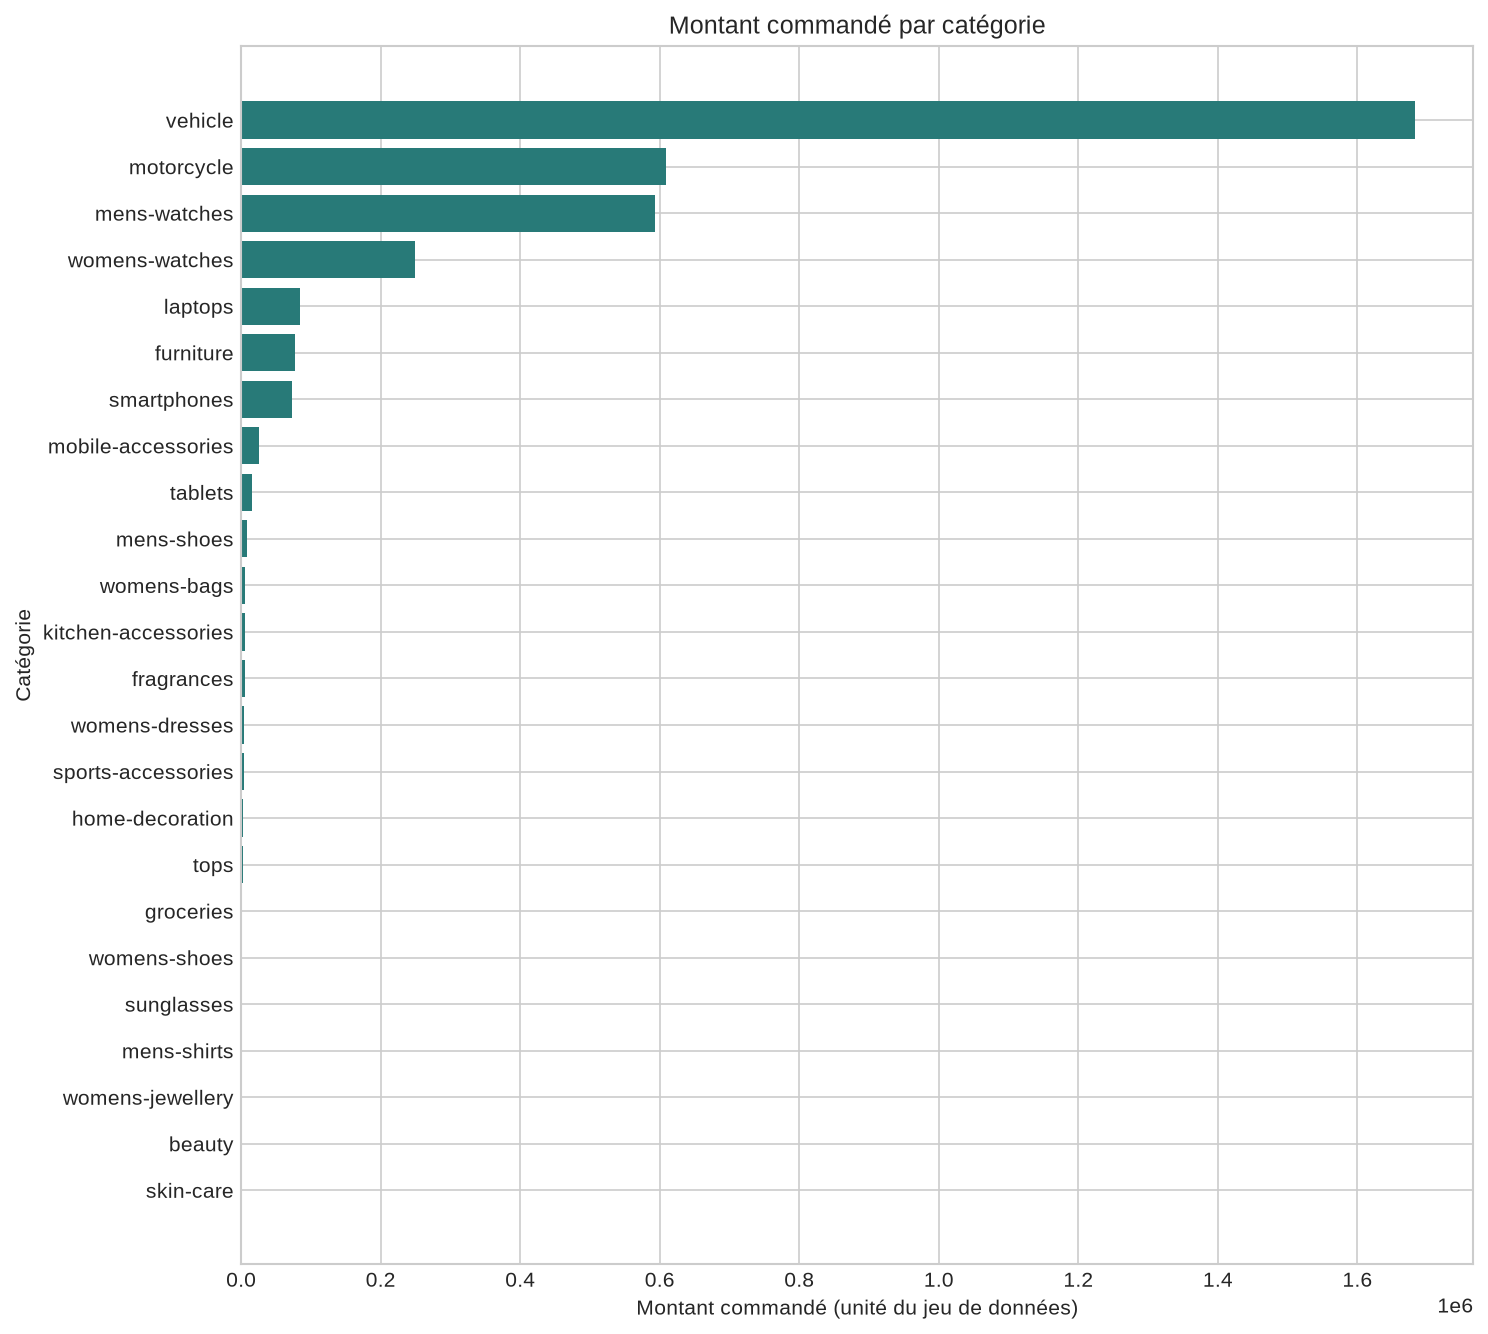

La catégorie vehicle représente le montant commandé le plus élevé : 1,682,064.05.


In [8]:
dossier_figures = Path("figures")
dossier_figures.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(10, 9))
ordre = ca_categories.sort_values("discounted_line_total")
ax.barh(ordre["category"], ordre["discounted_line_total"], color="#287a78")
ax.set_title("Montant commandé par catégorie")
ax.set_xlabel("Montant commandé (unité du jeu de données)")
ax.set_ylabel("Catégorie")
fig.tight_layout()
fig.savefig(dossier_figures / "ca_par_categorie.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(dossier_figures / "ca_par_categorie.png")))
plt.close(fig)
premiere = ca_categories.iloc[0]
print(f"La catégorie {premiere['category']} représente le montant commandé le plus élevé : {premiere['discounted_line_total']:,.2f}.")

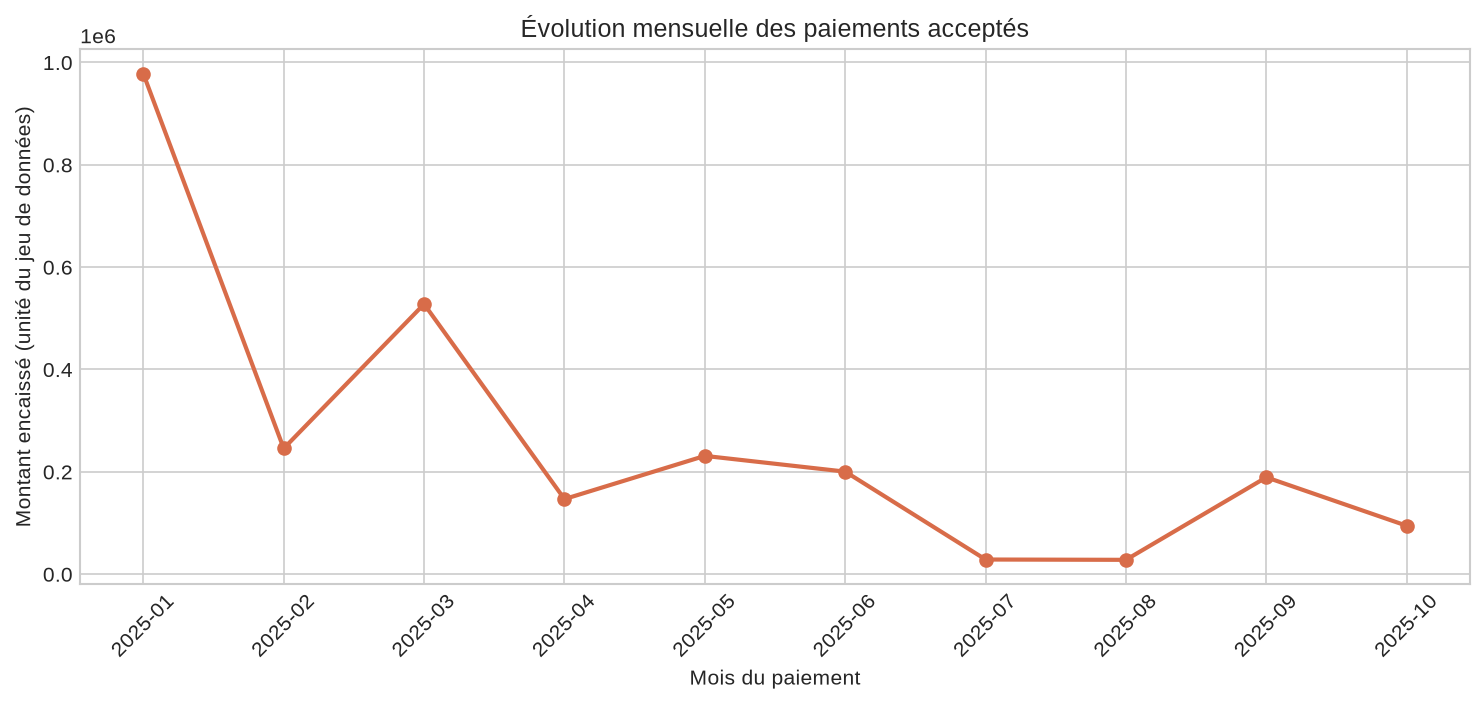

Le mois le plus élevé est 2025-01 avec 977,810.05 encaissés.
Les dates sont simulées et ne décrivent pas un historique commercial réel.


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(ca_mensuel["mois"], ca_mensuel["amount"], marker="o", color="#d86c49", linewidth=2)
ax.set_title("Évolution mensuelle des paiements acceptés")
ax.set_xlabel("Mois du paiement")
ax.set_ylabel("Montant encaissé (unité du jeu de données)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(dossier_figures / "evolution_mensuelle.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(dossier_figures / "evolution_mensuelle.png")))
plt.close(fig)
pic = ca_mensuel.loc[ca_mensuel["amount"].idxmax()]
print(f"Le mois le plus élevé est {pic['mois']} avec {pic['amount']:,.2f} encaissés.")
print("Les dates sont simulées et ne décrivent pas un historique commercial réel.")

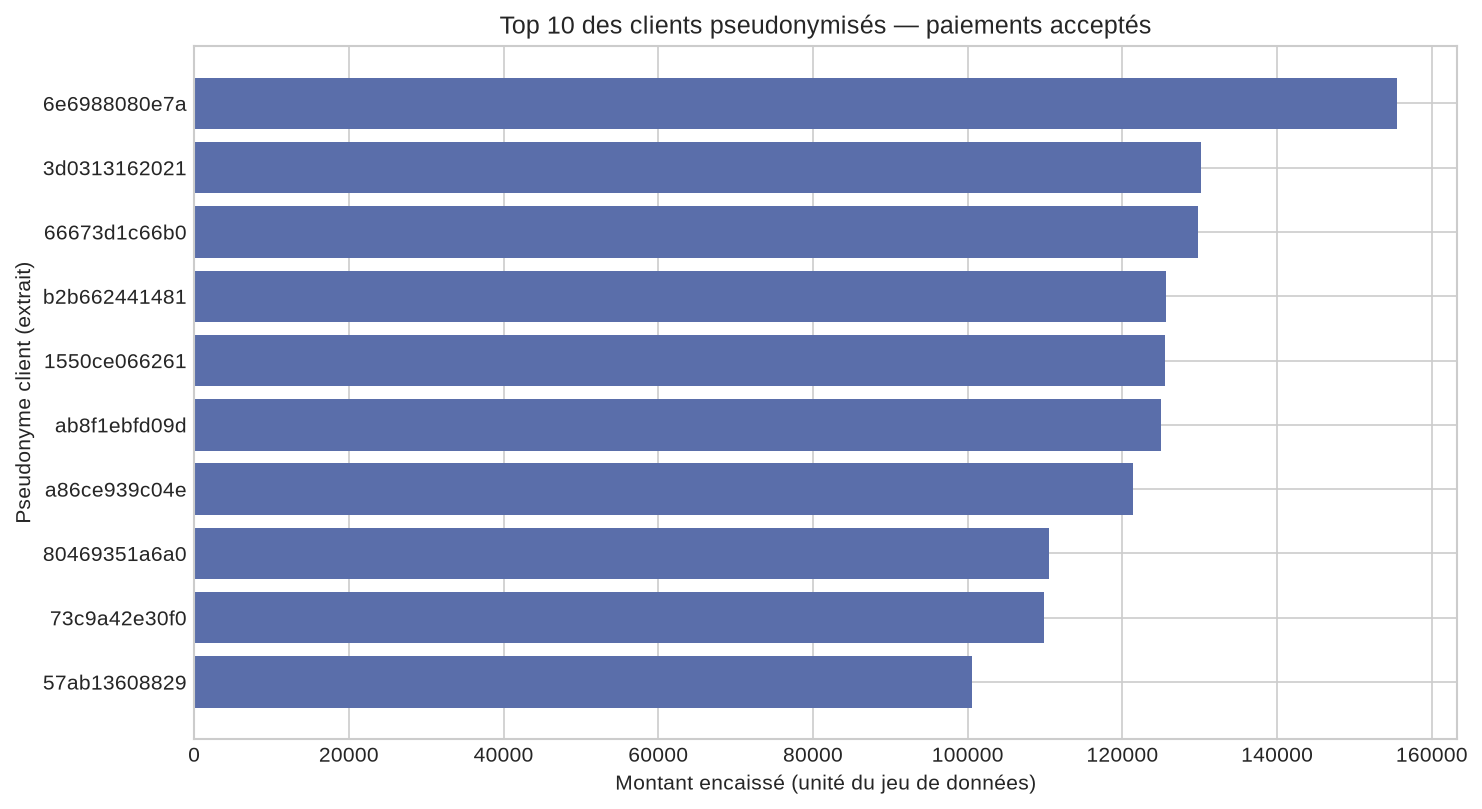

Le premier client pseudonymisé totalise 155,507.16 encaissés.


In [10]:
etiquettes = top_clients["user_id_pseudo"].str[:12]
if etiquettes.nunique() != len(etiquettes):
    etiquettes = top_clients["user_id_pseudo"]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(etiquettes, top_clients["amount"], color="#5a6eaa")
ax.invert_yaxis()
ax.set_title("Top 10 des clients pseudonymisés — paiements acceptés")
ax.set_xlabel("Montant encaissé (unité du jeu de données)")
ax.set_ylabel("Pseudonyme client (extrait)")
fig.tight_layout()
fig.savefig(dossier_figures / "top_10_clients.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(dossier_figures / "top_10_clients.png")))
plt.close(fig)
print(f"Le premier client pseudonymisé totalise {top_clients.iloc[0]['amount']:,.2f} encaissés.")

## 7. Limites et précautions

- HMAC remplace l’identifiant, mais les observations restent reliables entre elles : ce n’est pas de l’anonymisation.
- Une personne possédant la clé et une liste d’identifiants peut recalculer les pseudonymes. Des recoupements peuvent aussi permettre d’identifier un client.
- Garder la clé hors du dépôt, limiter les accès aux fichiers Parquet et ne conserver que les données utiles.
- Les dates sont fictives. Dans le TP2, la date du paiement est la date la plus ancienne du panier ; certaines lignes d’un même panier portent des dates différentes.
- La base MongoDB locale conserve les données sources. Le dashboard Streamlit lit uniquement les deux exports pseudonymisés.